# KT-02 · Notebook 01 — Tự code backpropagation bằng NumPy (PHẦN 1)

Mục tiêu: mạng **2→4→1** giải XOR, **chỉ NumPy** — tự viết forward, tự viết backward, rồi **kiểm chứng gradient**.
Mã nguồn nằm trong `src/nn_numpy.py` và `src/gradient_check.py`; notebook này chạy và giải thích kết quả.

Các bước README được phủ: **1 → 5** (+ 3 phần mở rộng: Adam, kiểm chứng BatchNorm, bề mặt loss).

In [12]:
import sys, os, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
sys.path.insert(0, "../src")          
os.makedirs("../reports", exist_ok=True)
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## Bước 1 — Mạng 2→4→1 giải XOR

Forward: `z1 = X@W1+b1 → a1 = σ(z1) → z2 = a1@W2+b2 → a2 = σ(z2)`, loss `MSE = mean((a2−y)²)`.
Backward = quy tắc dây chuyền, đi ngược: `∂L/∂a2 → ×σ'(z2) → ∂L/∂W2, ∂L/∂a1 → ×σ'(z1) → ∂L/∂W1`.
Lưu ý `y` phải có shape `(4,1)`, nếu là `(4,)` thì `a2 - y` broadcast thành ma trận 4×4 và loss sai âm thầm.

In [13]:
from nn_numpy import MLP, LogisticNoHidden, train, X_XOR, Y_XOR
from gradient_check import check_network, kiem_chung_gradient
from nn_numpy import SGD, Adam
print("X_XOR:", X_XOR.shape, "| Y_XOR:", Y_XOR.shape)
print("Số tham số:", sum(v.size for v in MLP().p.values()))

X_XOR: (4, 2) | Y_XOR: (4, 1)
Số tham số: 17


## Bước 2 — Kiểm chứng gradient (sai lệch phải < 1e-7)

Với mỗi tham số: dịch `+eps`, `−eps`, tính loss hai lần → gradient số `(f₊−f₋)/(2·eps)`. So với gradient của backprop.

In [14]:
net = MLP(seed=1)
print("Kiểm chứng gradient mạng 2→4→1 (eps=1e-5):")
worst = check_network(net, X_XOR, Y_XOR)
assert worst < 1e-7

Kiểm chứng gradient mạng 2→4→1 (eps=1e-5):
  W1     sai lệch lớn nhất: 3.88e-12 → ĐÚNG
  b1     sai lệch lớn nhất: 3.96e-12 → ĐÚNG
  W2     sai lệch lớn nhất: 2.97e-12 → ĐÚNG
  b2     sai lệch lớn nhất: 2.89e-12 → ĐÚNG
=> Sai lệch lớn nhất toàn mạng: 3.96e-12 → ĐÚNG


### Kiểm chứng "bắt được lỗi" thật không? — thử cố tình viết sai

Một bộ kiểm chứng chỉ có giá trị nếu nó báo **SAI** khi code sai. Ở đây ta cố tình *quên chia N* (cạm bẫy số 3 trong README).

In [15]:
class MLPQuenChiaN(MLP):
    def backward(self):
        g = super().backward()
        return {k: v * len(self.y) for k, v in g.items()}      # gradient to gấp N lần
print("Backprop bị lỗi (quên chia N):")
_ = check_network(MLPQuenChiaN(seed=1), X_XOR, Y_XOR)

Backprop bị lỗi (quên chia N):
  W1     sai lệch lớn nhất: 3.54e-02 → SAI
  b1     sai lệch lớn nhất: 3.67e-02 → SAI
  W2     sai lệch lớn nhất: 9.39e-02 → SAI
  b2     sai lệch lớn nhất: 1.01e-01 → SAI
=> Sai lệch lớn nhất toàn mạng: 1.01e-01 → SAI


### Ảnh hưởng của `eps` (cạm bẫy số 2)

`eps` quá lớn → sai số xấp xỉ; `eps` quá nhỏ → sai số làm tròn số thực lấn át.

In [16]:
rows = []
for eps in [1e-1, 1e-3, 1e-5, 1e-8, 1e-10, 1e-12]:
    w = check_network(MLP(seed=1), X_XOR, Y_XOR, eps=eps, verbose=False)
    rows.append((f"{eps:.0e}", f"{w:.2e}", "ĐÚNG" if w < 1e-7 else "vượt ngưỡng 1e-7 dù backprop đúng"))
pd.DataFrame(rows, columns=["eps", "sai lệch lớn nhất", "kết luận"])

,eps,sai lệch lớn nhất,kết luận
0,1e-01,7.56e-05,vượt ngưỡng 1e-7 dù backprop đúng
1,1e-03,7.57e-09,ĐÚNG
2,1e-05,3.96e-12,ĐÚNG
3,1e-08,3.33e-09,ĐÚNG
4,1e-10,3.37e-07,vượt ngưỡng 1e-7 dù backprop đúng
5,1e-12,6.92e-05,vượt ngưỡng 1e-7 dù backprop đúng


### Mở rộng 2 — kiểm chứng gradient cho mạng sâu tổng quát (`src/nn_numpy.py`)

Mạng tổng quát (softmax + cross-entropy) có đủ **7 activation** và **BatchNorm tự cài (cả forward lẫn backward)**.
Kiểm chứng mọi tham số (W, b, γ, β) với bias/γ/β được làm lệch khỏi giá trị khởi đầu để kiểm chứng đầy đủ.

In [17]:
from nn_numpy import DeepNet
from nn_numpy import ACTIVATIONS, PRETTY
from nn_numpy import load_image_data
Xtr, Xva, ytr, yva, ten_data = load_image_data()
rng = np.random.RandomState(0)
Xs, ys = Xtr[:8], ytr[:8]
rows = []
for act in ACTIVATIONS:
    row = [PRETTY[act]]
    for bn in (False, True):
        net = DeepNet([64, 10, 8, 10], act=act, init="he", batchnorm=bn, seed=1)
        for k in net.p:
            if k[0] in "bg": net.p[k] += rng.randn(*net.p[k].shape) * 0.1      # b, g(amma), be(ta)
        row.append(f"{check_network(net, Xs, ys, verbose=False):.1e}")
    rows.append(row)
df = pd.DataFrame(rows, columns=["activation", "không BN", "có BatchNorm"])

print("Sai lệch gradient lớn nhất (ngưỡng 1e-7):")
df

Sai lệch gradient lớn nhất (ngưỡng 1e-7):


,activation,không BN,có BatchNorm
0,Sigmoid,4.3e-11,4.9e-11
1,Tanh,4.1e-11,5.9e-11
2,ReLU,4.0e-11,5.8e-11
3,LeakyReLU,4.5e-11,9.7e-11
4,ELU,4.0e-11,6.0e-11
5,GELU,4.3e-11,2.8e-10
6,SiLU/Swish,4.9e-11,7.1e-11


## Bước 3 — Train 10.000 epoch và tìm "khúc gãy" kinh điển

Khởi tạo nhỏ (`scale=0.3`) + `lr=0.5`. Ban đầu mạng chỉ học được lời giải "đoán 0.5 cho mọi điểm" (MSE=0.25).
Loss **đứng ở cao nguyên ~0.25** một lúc rồi **rơi đột ngột** khi đối xứng bị phá vỡ.

Loss đầu 0.2563 | cao nguyên 0–1590 | loss<0.1 tại epoch 2399 | loss cuối 0.00071


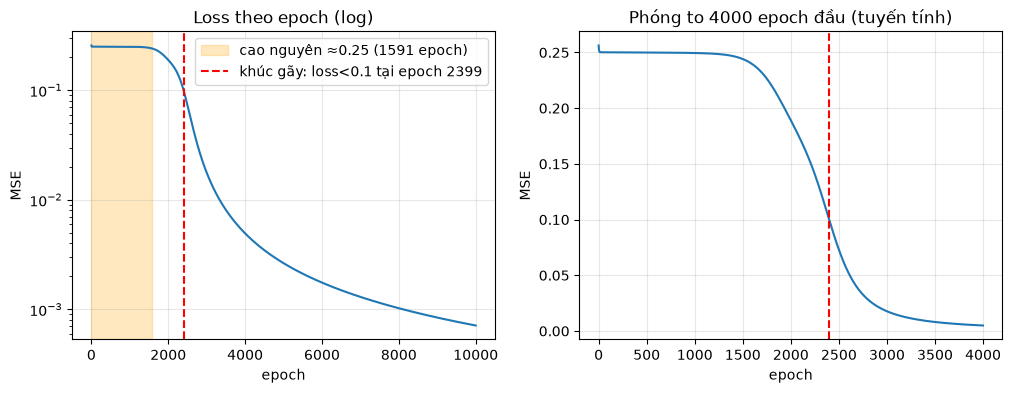

In [18]:
net = MLP(seed=0, scale=0.3)
loss = train(net, X_XOR, Y_XOR, epochs=10000, lr=0.5)
plateau = np.where((loss > 0.24) & (loss < 0.26))[0]
drop = int(np.argmax(loss < 0.1))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(loss, lw=1.5); ax[0].set_yscale("log")
ax[0].axvspan(plateau[0], plateau[-1], color="orange", alpha=.25, label=f"cao nguyên ≈0.25 ({len(plateau)} epoch)")
ax[0].axvline(drop, color="r", ls="--", label=f"khúc gãy: loss<0.1 tại epoch {drop}")
ax[0].set(title="Loss theo epoch (log)", xlabel="epoch", ylabel="MSE"); ax[0].legend()
ax[1].plot(loss[:4000], lw=1.5); ax[1].axvline(drop, color="r", ls="--")
ax[1].set(title="Phóng to 4000 epoch đầu (tuyến tính)", xlabel="epoch", ylabel="MSE")

print(f"Loss đầu {loss[0]:.4f} | cao nguyên {plateau[0]}–{plateau[-1]} | loss<0.1 tại epoch {drop} | loss cuối {loss[-1]:.5f}")

## Bước 4 — Ranh giới quyết định & xác nhận giải đúng XOR

Dự đoán: [0.03  0.975 0.974 0.026] ≈ [0, 1, 1, 0]  | accuracy = 100%


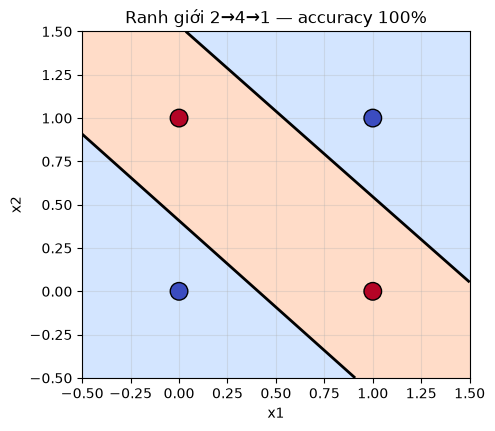

In [19]:
def ve_ranh_gioi(predict, ax, tieu_de, X=X_XOR, y=Y_XOR, lim=(-0.5, 1.5)):
    g = np.linspace(*lim, 200); xx, yy = np.meshgrid(g, g)
    Z = predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[0, 0.5, 1], colors=["#cfe3ff", "#ffd9c2"], alpha=.9)
    ax.contour(xx, yy, Z, levels=[0.5], colors="k", linewidths=2)
    ax.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap="coolwarm", s=160, edgecolors="k", zorder=3)
    ax.set_title(tieu_de); ax.set_xlabel("x1"); ax.set_ylabel("x2")

pred = net.predict(X_XOR).ravel()
acc = ((pred > 0.5) == Y_XOR.ravel()).mean()
fig, ax = plt.subplots(figsize=(5, 4.5))
ve_ranh_gioi(net.predict, ax, f"Ranh giới 2→4→1 — accuracy {acc:.0%}")

print("Dự đoán:", pred.round(3), "≈ [0, 1, 1, 0]  | accuracy =", f"{acc:.0%}")
assert acc == 1.0

## Bước 5  — Bỏ tầng ẩn (2→1) ⇒ KHÔNG giải được XOR

Không tầng ẩn = hồi quy logistic: ranh giới luôn là **một đường thẳng**. Hai chứng cứ:
1. Huấn luyện: loss kẹt ở 0.25, mọi dự đoán ≈ 0.5.
2. Vét cạn: thử 360 hướng × 401 ngưỡng, **không đường thẳng nào** phân loại đúng cả 4 điểm.

seed 0: loss cuối = 0.2500 | dự đoán = [0.5 0.5 0.5 0.5]
seed 1: loss cuối = 0.2500 | dự đoán = [0.5 0.5 0.5 0.5]
seed 2: loss cuối = 0.2500 | dự đoán = [0.5 0.5 0.5 0.5]

Độ chính xác TỐT NHẤT của mọi đường thẳng thử được: 75%  (XOR cần 100%)


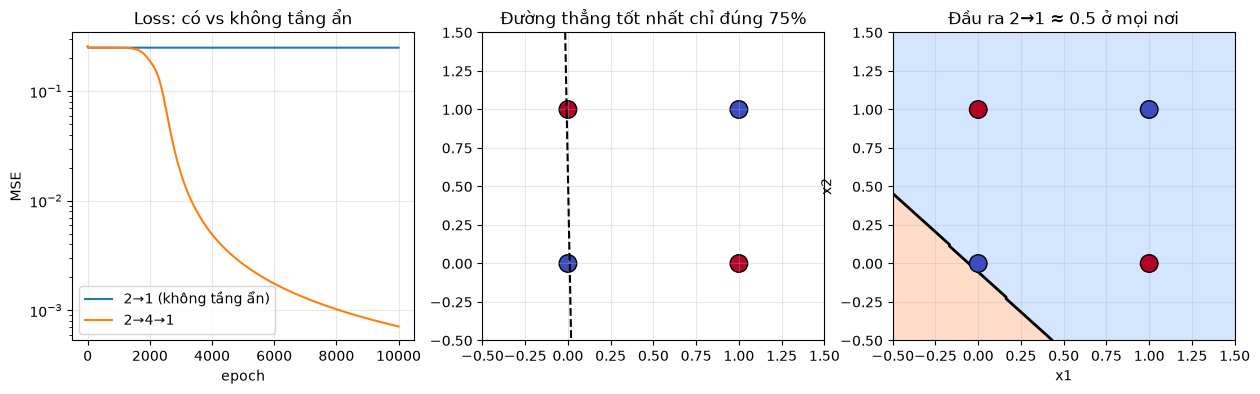

In [20]:
res = []
for seed in range(3):
    n0 = LogisticNoHidden(seed=seed)
    l0 = train(n0, X_XOR, Y_XOR, epochs=10000, lr=1.0)
    res.append((seed, l0[-1], n0.predict(X_XOR).ravel().round(3)))
    print(f"seed {seed}: loss cuối = {l0[-1]:.4f} | dự đoán = {res[-1][2]}")

# vét cạn mọi đường thẳng
best, best_line = 0, None
for th in np.linspace(0, 2 * np.pi, 360, endpoint=False):
    w = np.array([np.cos(th), np.sin(th)])
    for b in np.linspace(-2, 2, 401):
        a = ((X_XOR @ w + b > 0).astype(float) == Y_XOR.ravel()).mean()
        if a > best: best, best_line = a, (w, b)
print(f"\nĐộ chính xác TỐT NHẤT của mọi đường thẳng thử được: {best:.0%}  (XOR cần 100%)")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(l0, label="2→1 (không tầng ẩn)"); ax[0].plot(loss, label="2→4→1"); ax[0].set_yscale("log")
ax[0].set(title="Loss: có vs không tầng ẩn", xlabel="epoch", ylabel="MSE"); ax[0].legend()
ax[1].scatter(X_XOR[:, 0], X_XOR[:, 1], c=Y_XOR.ravel(), cmap="coolwarm", s=160, edgecolors="k")
w, b = best_line; xs = np.linspace(-.5, 1.5, 10)
ax[1].plot(xs, -(w[0] * xs + b) / w[1] if abs(w[1]) > 1e-9 else xs, "k--")
ax[1].set(xlim=(-.5, 1.5), ylim=(-.5, 1.5), title=f"Đường thẳng tốt nhất chỉ đúng {best:.0%}")
ve_ranh_gioi(n0.predict, ax[2], "Đầu ra 2→1 ≈ 0.5 ở mọi nơi")

assert best < 1.0

## Mở rộng 1 — Tự cài Adam, so sánh với SGD trên XOR

Hai optimizer đều tự viết trong `src/optim.py`. 10 seed, đếm số epoch để loss < 0.01 (tối đa 5000).

,optimizer,số seed đạt loss<0.01,epoch trung vị,epoch từng seed (None = chưa đạt)
0,SGD lr=1.0,9/10,1670,"[1670, 1562, 1202, 4452, None, 1589, 1768, 272..."
1,Adam lr=0.1,10/10,68,"[77, 102, 53, 65, 70, 69, 76, 64, 58, 66]"


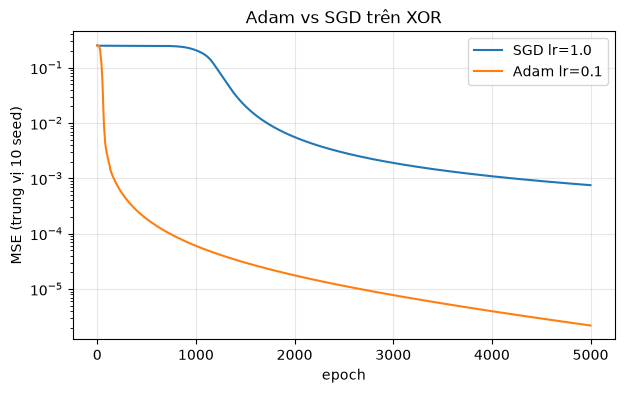

In [21]:
def epoch_dat(l, thr=0.01):
    return int(np.argmax(l < thr)) if (l < thr).any() else None
cfg = {"SGD lr=1.0": lambda: SGD(1.0), "Adam lr=0.1": lambda: Adam(0.1)}
ket_qua, curves = {}, {}
for ten, mk in cfg.items():
    ep, cs = [], []
    for s in range(10):
        n = MLP(seed=s, scale=0.3); l = train(n, X_XOR, Y_XOR, epochs=5000, opt=mk())
        ep.append(epoch_dat(l)); cs.append(l)
    ket_qua[ten], curves[ten] = ep, np.array(cs)
rows = []
for ten, ep in ket_qua.items():
    ok = [e for e in ep if e is not None]
    rows.append((ten, f"{len(ok)}/10", f"{np.median(ok):.0f}" if ok else "-", ep))
fig, ax = plt.subplots(figsize=(7, 4))
for ten, cs in curves.items():
    ax.plot(np.median(cs, axis=0), label=ten)
ax.set(yscale="log", xlabel="epoch", ylabel="MSE (trung vị 10 seed)", title="Adam vs SGD trên XOR"); ax.legend()

pd.DataFrame(rows, columns=["optimizer", "số seed đạt loss<0.01", "epoch trung vị", "epoch từng seed (None = chưa đạt)"])

## Mở rộng 3 — Bề mặt loss 3D

Mạng XOR có 17 tham số nên không vẽ trực tiếp được. Ta lấy **lát cắt 2 chiều**: thay đổi `W1[0,0]` và `W2[0,0]`, giữ nguyên các tham số khác ở giá trị đã học.
Đây là một lát cắt của bề mặt, không phải toàn bộ bề mặt.

loss thấp nhất trên lưới: 0.0006 | loss tại nghiệm đã học: 0.00071 | cao nguyên (max): 0.498


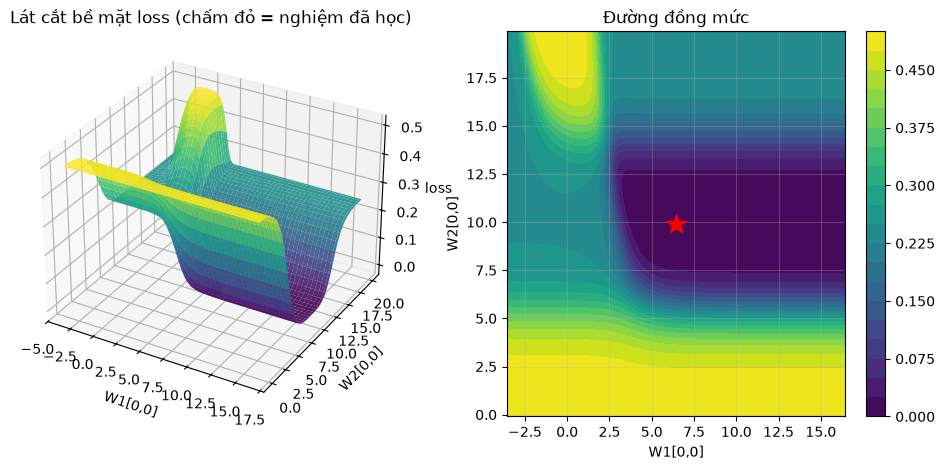

In [22]:
import copy
from mpl_toolkits.mplot3d import Axes3D  # noqa
base = copy.deepcopy(net)
w1_0, w2_0 = base.p["W1"][0, 0], base.p["W2"][0, 0]
g1 = np.linspace(w1_0 - 10, w1_0 + 10, 90); g2 = np.linspace(w2_0 - 10, w2_0 + 10, 90)
Z = np.zeros((len(g1), len(g2)))
t = copy.deepcopy(base)
for i, a in enumerate(g1):
    for j, b in enumerate(g2):
        t.p["W1"][0, 0], t.p["W2"][0, 0] = a, b
        Z[i, j] = t.forward(X_XOR, Y_XOR)
G1, G2 = np.meshgrid(g1, g2, indexing="ij")
fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(G1, G2, Z, cmap="viridis", alpha=.9, linewidth=0)
ax.scatter([w1_0], [w2_0], [base.forward(X_XOR, Y_XOR)], c="r", s=60)
ax.set(xlabel="W1[0,0]", ylabel="W2[0,0]", zlabel="loss", title="Lát cắt bề mặt loss (chấm đỏ = nghiệm đã học)")
ax2 = fig.add_subplot(1, 2, 2)
cs = ax2.contourf(G1, G2, Z, levels=20, cmap="viridis"); plt.colorbar(cs, ax=ax2)
ax2.plot(w1_0, w2_0, "r*", ms=15); ax2.set(xlabel="W1[0,0]", ylabel="W2[0,0]", title="Đường đồng mức")

print(f"loss thấp nhất trên lưới: {Z.min():.4f} | loss tại nghiệm đã học: {base.forward(X_XOR, Y_XOR):.5f} | cao nguyên (max): {Z.max():.3f}")